id: notebooks/08_sun_first_target.ipynb

the Sun as the first target: two horns on one B210 – signal strength, baseline choice, raw-signal checks, transit, radio diameter

<!-- notebooks/08_sun_first_target.ipynb -- the Sun as the first target (Interferosim 0.8.1) -->
# 08 – The Sun as the first target

---
  DI Erich Schubert, 07925151
  


Before the 11.5 km baseline both horns are tested at one site on **one** B210. This notebook works through that test: expected signal, sensible baseline length, fringe rate, the checks on the raw signals, the transit with fixed horns – and what it yields about the Sun itself: its **radio diameter at 21 cm**.

**Why the Sun first.** In a test set-up the sources of error are worked off one by one:

| property | consequence |
|---|---|
| ≈ 5 · 10⁵ Jy at 21 cm | fringes visible **without any search**, correlation coefficient ≈ 150 × that of the OH maser M1 on two 3 m dishes |
| one B210, two RX channels | common LO and clock: **no clock problem, no time transfer, no coherence limit** |
| baseline < 50 m | geometric delay below 1/Δν: **no delay compensation**, correlation at zero lag |
| fringe period of minutes | the fringes can be followed by eye in the dumps |

If something does not work in this set-up, it is hardware or software – not physics.

Package: `interferosim.observation` – `sun_flux_jy`, `solar_transit_mjd`, `SolarTransitSimulator`, `disc_amplitude`, `fit_disc_diameter` (module `solar`, new in 0.8.1); the IQ simulation and the FX correlator of notebooks 03 and 05. Origin: Appendix B of the teaching material.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT, HI_21CM, K_BOLTZMANN, JANSKY
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel, FieldCenter
from interferosim.sky.components import DiscSource
from interferosim.observation import (Observation, VisibilitySimulator, TransitSimulator, SolarTransitSimulator,
                                      sun_flux_jy, sun_radec_deg, solar_transit_mjd, disc_amplitude,
                                      fit_disc_diameter)
from interferosim.signal import IQSimulator, FXCorrelator, StationErrors

CFG = Path("..") / "configs"
DATE = "2026-11-01"
LAM = C_LIGHT / HI_21CM
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
horn = Antenna.from_toml(CFG / "antennas" / "horn_15dbi.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
horns = Array.from_toml(CFG / "sites" / "two_horns_10m.toml")       # H1, H2: 10 m east-west, one B210

sun = SkyModel.from_json(CFG / "skies" / "sun_21cm.json")           # quiet Sun, 34', limb +50 %
T_TRANSIT = solar_transit_mjd(DATE, site.lon_deg)
ra_sun, dec_sun = (float(x) for x in sun_radec_deg(T_TRANSIT))
sun.center = FieldCenter("Sun", ra_sun, dec_sun)
disc = sun.components[0]

def utc(mjd):
    from datetime import datetime, timezone
    return datetime.fromtimestamp((mjd - 40587.0) * 86400.0, timezone.utc).strftime("%H:%M:%S UTC")

def horn_pair(b_m, az="east"):
    """Two horns on one B210, b_m metres apart (east-west or north-south)."""
    e, n = (b_m, 0.0) if az == "east" else (0.0, b_m)
    return Array(site, [Station.from_enu("H1", site, 0, 0, 0, horn), Station.from_enu("H2", site, e, n, 0, horn)],
                 receiver=b210, name=f"two horns {b_m:g} m {'east-west' if az == 'east' else 'north-south'}")

print(f"Sun on {DATE}: transit at Wilhelmsburg {utc(T_TRANSIT)}, RA {ra_sun:.2f} deg, Dec {dec_sun:+.2f} deg, "
      f"elevation {90 - site.lat_deg + dec_sun:.1f} deg")

Sun on 2026-11-01: transit at Wilhelmsburg 10:40:33 UTC, RA 216.63 deg, Dec -14.50 deg, elevation 27.4 deg


## 1. How strong is the Sun at 21 cm?

The 21 cm emission of the quiet Sun comes from the transition region between chromosphere and lower corona. Its brightness temperature is about $10^5$ K, and the **radio disc is larger than the optical one** – about 34′ instead of 32′. The flux density follows directly:

$$S = \frac{2k\,T_b\,\Omega_\odot}{\lambda^2}, \qquad \Omega_\odot = \pi\,(\theta/2)^2 .$$

Both values vary with the solar cycle by about a factor of two, during bursts by orders of magnitude. For a calibrated measurement the daily activity index (Penticton F10.7 at 2800 MHz) is the reference.

Antenna temperature $T_A = S A_\mathrm{eff}/2k$, correlation coefficient of a baseline $\rho = |V|\,T_A/(T_\mathrm{sys}+T_A)$ (for an unresolved source, $|V| = 1$), signal-to-noise ratio of one dump $\rho\sqrt{2\,\Delta\nu\,t}$.

In [2]:
S_SUN = sun_flux_jy(1e5, 34 / 60)
print(f"S = {S_SUN:,.0f} Jy = {S_SUN / 1e4:.0f} SFU   (model file: {disc.flux_jy:,.0f} Jy)\n")
bw, tsys = b210.bandwidth_hz, b210.t_sys_k
print(f"{'antennas':<16s} {'A_eff [m2]':>10s} {'HPBW [deg]':>10s} {'T_A [K]':>8s} {'T_A/T_sys':>9s} "
      f"{'rho':>7s} {'S/N 1 s':>8s} {'S/N 5 s':>8s}")
for name, a1, a2 in [("horn x horn", horn, horn), ("horn x dish", horn, dish), ("dish x dish", dish, dish)]:
    ae = np.sqrt(a1.effective_area(HI_21CM) * a2.effective_area(HI_21CM))
    ta = S_SUN * JANSKY * ae / (2 * K_BOLTZMANN)
    rho = ta / (tsys + ta)
    hp = np.sqrt(a1.hpbw_deg(HI_21CM) * a2.hpbw_deg(HI_21CM)) if hasattr(a1, "hpbw_deg") else float("nan")
    print(f"{name:<16s} {ae:10.2f} {hp:10.1f} {ta:8.1f} {ta / tsys:9.2f} {rho:7.3f} "
          f"{rho * np.sqrt(2 * bw * 1):8.0f} {rho * np.sqrt(2 * bw * 5):8.0f}")
print("\nfor comparison, OH maser M1 (70 Jy) on two 3 m dishes: rho =",
      f"{70 * JANSKY * dish.effective_area(HI_21CM) / (2 * K_BOLTZMANN) / tsys:.1e}")

S = 476,208 Jy = 48 SFU   (model file: 476,200 Jy)

antennas         A_eff [m2] HPBW [deg]  T_A [K] T_A/T_sys     rho  S/N 1 s  S/N 5 s
horn x horn            0.11       33.9     19.3      0.16   0.139      278      621
horn x dish            0.69       12.8    118.9      0.99   0.498      995     2226
dish x dish            4.24        4.8    731.4      6.10   0.859     1718     3842

for comparison, OH maser M1 (70 Jy) on two 3 m dishes: rho = 9.0e-04


**For the horns the Sun is comfortable:** $T_A \approx 19$ K on $T_\mathrm{sys} = 120$ K. **For a 3 m dish it is an imposition:** $T_A$ several times $T_\mathrm{sys}$ – the receiver chain must stay linear, otherwise one measures the compression of the amplifiers. An attenuator in front of the LNA is mandatory for solar observations with the dish, and the Y-factor calibration has to be repeated afterwards.

## 2. Which baseline? The Sun is an extended source

With 34′ the Sun is anything but a point source. Its visibility is the Hankel transform of the brightness profile; for a uniform disc of diameter $\theta$

$$V(q) = S\,\frac{2J_1(\pi\theta q)}{\pi\theta q}, \qquad B_\mathrm{null} = 1.2197\,\frac{\lambda}{\theta} \approx 26\ \mathrm{m}.$$

At 21 cm the limb is brightened; `DiscSource` models this with the profile $1 + a\,\rho^8$. Two operating points follow:

| baseline | purpose |
|---|---|
| **2 … 10 m** | first fringes: $\lvert V\rvert > 0.75$, maximum signal, everything uncritical |
| **10 … 38 m** | diameter measurement: $\lvert V\rvert$ passes through the first null |

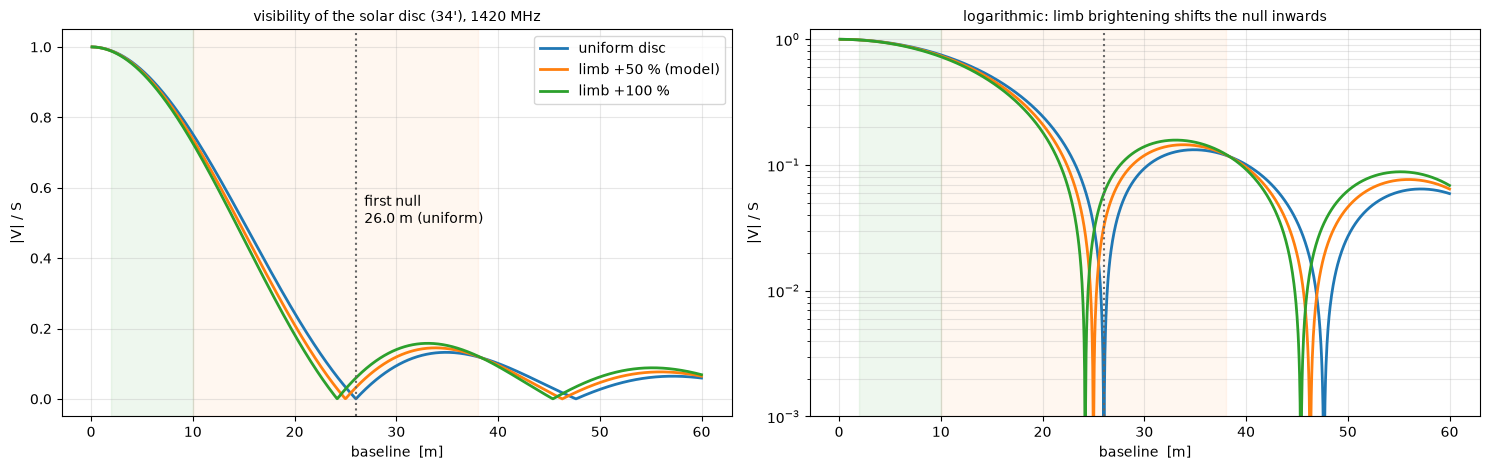

B =   2 m: |V| = uniform disc 0.989, limb +50 % 0.989, limb +100 % 0.988
B =   5 m: |V| = uniform disc 0.934, limb +50 % 0.930, limb +100 % 0.927
B =  10 m: |V| = uniform disc 0.752, limb +50 % 0.738, limb +100 % 0.727
B =  20 m: |V| = uniform disc 0.244, limb +50 % 0.211, limb +100 % 0.183
B =  26 m: |V| = uniform disc 0.001, limb +50 % 0.032, limb +100 % 0.059
B =  38 m: |V| = uniform disc 0.120, limb +50 % 0.121, limb +100 % 0.122


In [3]:
B = np.linspace(0.1, 60, 1200)
q = B / LAM
profiles = {"uniform disc": 0.0, "limb +50 % (model)": 0.5, "limb +100 %": 1.0}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for lab, a in profiles.items():
    d = DiscSource("Sun", 0, 0, 1.0, diameter_deg=34 / 60, limb=a)
    V = np.abs(d.visibility(q, np.zeros_like(q)))
    axes[0].plot(B, V, lw=2, label=lab); axes[1].semilogy(B, V, lw=2, label=lab)
B_null = 1.2197 * LAM / np.radians(34 / 60)
for ax in axes:
    ax.axvline(B_null, color="0.4", ls=":"); ax.axvspan(2, 10, color="C2", alpha=0.08); ax.axvspan(10, 38, color="C1", alpha=0.06)
    ax.set_xlabel("baseline  [m]"); ax.set_ylabel("|V| / S"); ax.grid(alpha=0.3, which="both")
axes[0].annotate(f"first null\n{B_null:.1f} m (uniform)", (B_null, 0.5), xytext=(6, 0), textcoords="offset points")
axes[0].set_title("visibility of the solar disc (34'), 1420 MHz", fontsize=10); axes[0].legend()
axes[1].set_ylim(1e-3, 1.2); axes[1].set_title("logarithmic: limb brightening shifts the null inwards", fontsize=10)
fig.tight_layout(); plt.show()
for b in (2, 5, 10, 20, 26, 38):
    print(f"B = {b:3d} m: |V| = " + ", ".join(f"{lab.split(' (')[0]} {abs(DiscSource('S', 0, 0, 1, diameter_deg=34/60, limb=a).visibility(np.array([b / LAM]), np.zeros(1))[0]):.3f}"
                                         for lab, a in profiles.items()))

## 3. Fringe rate, delay, elevation over the year

For the Sun the hour angle advances with the **solar** day, $2\pi/86400$ s, not the sidereal one (section 5). For an east–west baseline

$$f_\mathrm{fringe} = \frac{B}{\lambda}\cos\delta\,\cos H\,\omega_\odot ,\qquad \tau_g = \frac{B}{c}\cos\delta\,\sin H .$$

The rate is **largest** in the meridian and drops towards the horizon. The declination of the Sun moves between ±23.4°, which changes both the rate and the elevation. The delay of a 10 m baseline stays far inside the delay beam $\pm 1/2\Delta\nu$ (250 ns at 2 MHz) – no delay tracking is needed.

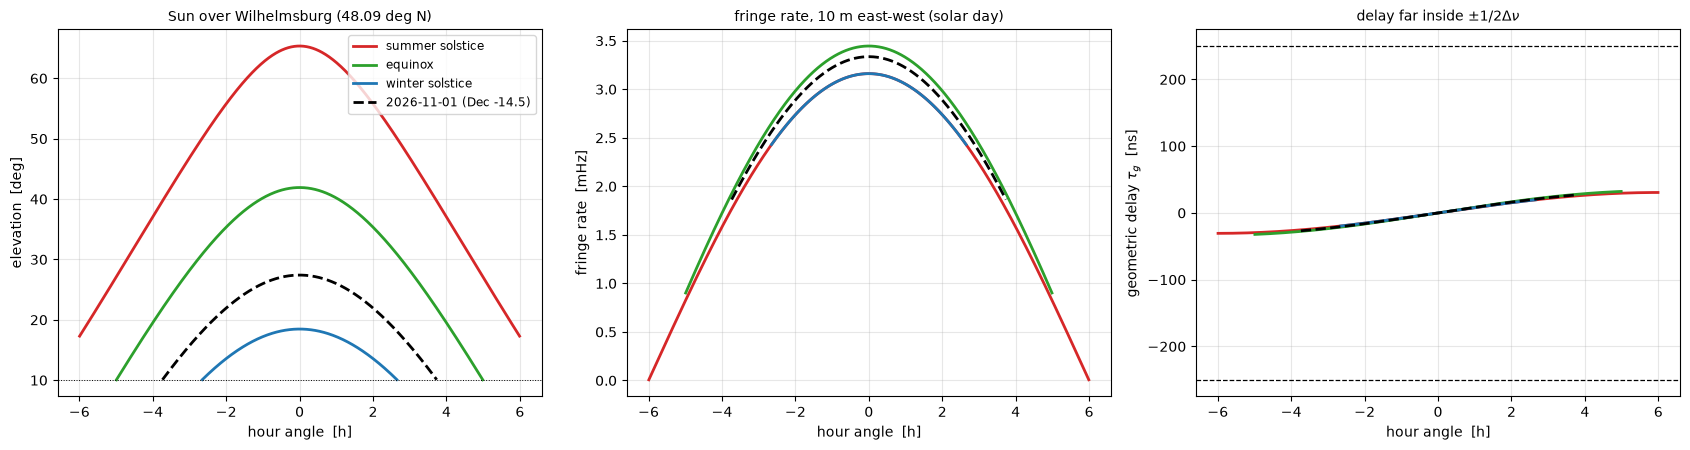

2026-11-01: fringe rate at transit 3.34 mHz, fringe period 5.0 min


In [4]:
arr10 = horn_pair(10)
cases = [(23.44, "summer solstice", "C3"), (0.0, "equinox", "C2"), (-23.44, "winter solstice", "C0"),
         (dec_sun, f"{DATE} (Dec {dec_sun:+.1f})", "k")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for dec, lab, col in cases:
    o = Observation(arr10, ra_deg=0.0, dec_deg=dec, ha_range_h=(-6, 6), t_int_s=60, min_elev_deg=-90)
    h = o.hour_angles() / 15
    el = o.elevation_deg()[0]
    up = el > 10
    ls = "--" if col == "k" else "-"
    axes[0].plot(h, np.where(up, el, np.nan), color=col, ls=ls, lw=2, label=lab)
    axes[1].plot(h[up], 1e3 * o.fringe_rate_hz()[0][up] * (1 - 1 / 365.2422), color=col, ls=ls, lw=2)
    axes[2].plot(h[up], 1e9 * o.delay_s()[0][up], color=col, ls=ls, lw=2)
axes[0].axhline(10, color="k", lw=0.7, ls=":"); axes[0].legend(fontsize=8.5)
axes[0].set(xlabel="hour angle  [h]", ylabel="elevation  [deg]", title=f"Sun over Wilhelmsburg ({site.lat_deg:.2f} deg N)")
axes[1].set(xlabel="hour angle  [h]", ylabel="fringe rate  [mHz]", title="fringe rate, 10 m east-west (solar day)")
half = 1e9 / (2 * b210.bandwidth_hz)
axes[2].axhline(half, color="k", ls="--", lw=0.9); axes[2].axhline(-half, color="k", ls="--", lw=0.9)
axes[2].set(xlabel="hour angle  [h]", ylabel=r"geometric delay $\tau_g$  [ns]", title="delay far inside $\\pm 1/2\\Delta\\nu$")
for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
f0 = 10 / LAM * np.cos(np.radians(dec_sun)) * 2 * np.pi / 86400
print(f"{DATE}: fringe rate at transit {1e3 * f0:.2f} mHz, fringe period {1 / f0 / 60:.1f} min")

## 4. Raw signals: two horns on one B210

IQ samples of both RX channels for 4 s at transit (covariance method of notebook 03, the horns track the Sun for these seconds). Because both channels share LO and clock, the stations need no clock or LO model; the correlation at zero lag directly shows the visibility, with its phase advancing at the natural fringe rate. The FX correlator (notebook 05) runs **without** model correction and fringe search.

Three checks belong to every session (Appendix B):

1. **cover the horns** – the correlation must drop to the noise level $1/\sqrt{N}$; what remains is crosstalk via LO, housing or ground;
2. **crosstalk** – simulated here as a common signal of 1 % of the system power in both channels: with covered horns it stays as a constant, non-rotating correlation;
3. **channel phase** – the AD9361 sets the phase between the channels anew at every retune: constant afterwards, but unknown. A noise source with a power splitter on both inputs measures it (here an offset of 70° is assumed).

expected: rho = 0.1025, phase +2.4 deg (at t = 2 s)
noise level 1/sqrt(N) = 3.5e-04

Sun                        |rho| = 0.1027  phase    +2.6 deg; phase per second: +1.2, +2.0, +3.2, +4.5
horns covered              |rho| = 0.0005  phase   +50.0 deg; phase per second: -133.5, +83.0, -3.1, +62.8
covered + crosstalk 1 %    |rho| = 0.0103  phase    +2.4 deg; phase per second: -5.7, +8.4, -0.0, +7.6


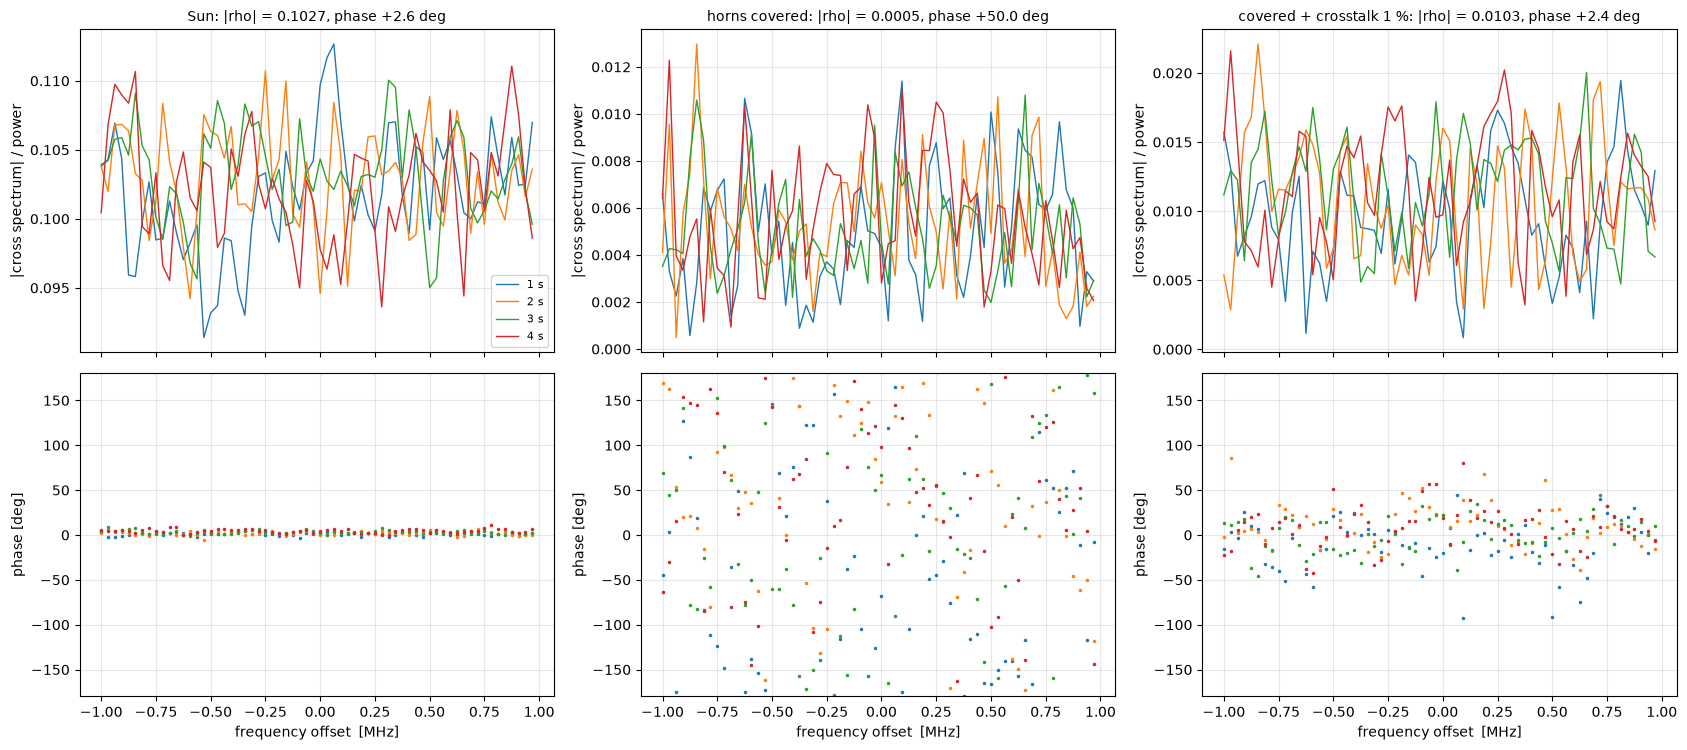

In [5]:
fx = FXCorrelator(nfft=64, t_int_s=1.0)

def corr_stats(blocks):
    x1, x2 = blocks["H1"].data, blocks["H2"].data
    c = np.mean(x1 * np.conj(x2))
    return c / np.sqrt(np.mean(np.abs(x1) ** 2) * np.mean(np.abs(x2) ** 2))

sim = IQSimulator(sun, horns, seed=3)
blocks = sim.simulate(4.0, lha0_deg=0.0)
covered = IQSimulator(sun, horns, seed=4, sky_signal=False).simulate(4.0, 0.0)

def add_crosstalk(bl, level=0.01, seed=9):
    """Common signal (e.g. LO leakage) of power level x the system power in both channels."""
    rng = np.random.default_rng(seed)
    n = bl["H1"].data.size
    p = np.mean(np.abs(bl["H1"].data) ** 2)
    z = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) * np.sqrt(level * p / 2)
    from dataclasses import replace
    return {k: replace(v, data=(v.data + z).astype(np.complex64)) for k, v in bl.items()}

covered_xt = add_crosstalk(covered)
N = blocks["H1"].data.size
q0 = sim.uvw(np.array([2.0]), 0.0)[0, 0]
expect = sim.expected_visibility(0, 1, q0[0], q0[1]) * np.exp(-2j * np.pi * q0[2])
p_tot = b210.sefd_jy(horn, HI_21CM) + sim.station_sky_power_jy(0)
print(f"expected: rho = {abs(expect) / p_tot:.4f}, phase {np.degrees(np.angle(expect)):+.1f} deg (at t = 2 s)")
print(f"noise level 1/sqrt(N) = {1 / np.sqrt(N):.1e}\n")
fig, axes = plt.subplots(2, 3, figsize=(17, 7.6), sharex=True)
for col, (lab, bl) in enumerate([("Sun", blocks), ("horns covered", covered), ("covered + crosstalk 1 %", covered_xt)]):
    r = corr_stats(bl)
    vd = fx.correlate(bl, sim, 0.0, model=False)
    f_mhz = (vd.freq_hz - HI_21CM) / 1e6
    p = np.sqrt(np.mean(np.abs(bl["H1"].data) ** 2) * np.mean(np.abs(bl["H2"].data) ** 2))
    for k in range(vd.n_rows):
        axes[0, col].plot(f_mhz, np.abs(vd.vis[k]) / p, lw=1, label=f"{k + 1} s")
        axes[1, col].plot(f_mhz, np.degrees(np.angle(vd.vis[k])), ".", ms=3)
    axes[0, col].set_title(f"{lab}: |rho| = {abs(r):.4f}, phase {np.degrees(np.angle(r)):+.1f} deg", fontsize=10)
    axes[0, col].set_ylabel("|cross spectrum| / power"); axes[1, col].set_ylabel("phase [deg]")
    axes[1, col].set_xlabel("frequency offset  [MHz]"); axes[1, col].set_ylim(-180, 180)
    for ax in axes[:, col]: ax.grid(alpha=0.3)
    print(f"{lab:<26s} |rho| = {abs(r):.4f}  phase {np.degrees(np.angle(r)):+7.1f} deg; "
          f"phase per second: {', '.join(f'{x:+.1f}' for x in np.degrees(np.angle(vd.vis.mean(axis=1))))}")
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

With the Sun the correlation coefficient agrees with the prediction, and the phase advances by about 1.2° per second – the fringe rate of section 3. With covered horns only noise remains (|ρ| ≈ 1/√N). The crosstalk gives |ρ| ≈ 0.01 – thirty times the noise level – with a **constant** phase. That is the decisive distinction: a correlation from the sky rotates with the fringe rate, crosstalk does not.

**Channel phase.** After a retune the second channel carries an unknown, constant phase offset. A noise source fed to both inputs via a power splitter gives a correlation whose phase *is* this offset (cables of equal length); it is subtracted from all later measurements.

In [6]:
offset = np.radians(70.0)
errs = {"H2": StationErrors(lo_phase_rad=offset)}
sun_raw = IQSimulator(sun, horns, seed=3, errors=errs).simulate(4.0, 0.0)
# noise-source calibration: identical noise on both inputs, then the receiver noise and the channel phase
rng = np.random.default_rng(11)
n = sun_raw["H1"].data.size
ns = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) * np.sqrt(5e6 / 2)          # noise source, power 5 MJy equivalent
rx = [(rng.standard_normal(n) + 1j * rng.standard_normal(n)) * np.sqrt(b210.sefd_jy(horn, HI_21CM) / 2) for _ in range(2)]
cal = np.mean((ns + rx[0]) * np.conj((ns + rx[1]) * np.exp(1j * offset)))
phi_cal = np.angle(cal)
r_raw = corr_stats(sun_raw)
print(f"Sun with the channel offset    : phase {np.degrees(np.angle(r_raw)):+7.1f} deg   (true sky phase {np.degrees(np.angle(expect)):+.1f} deg)")
print(f"noise source on both inputs    : phase {np.degrees(-phi_cal):+7.1f} deg  -> channel offset of H2")
print(f"Sun after the calibration      : phase {np.degrees(np.angle(r_raw * np.exp(-1j * phi_cal))):+7.1f} deg")

Sun with the channel offset    : phase   -67.4 deg   (true sky phase +2.4 deg)
noise source on both inputs    : phase   +70.0 deg  -> channel offset of H2
Sun after the calibration      : phase    +2.6 deg


## 5. The transit with fixed horns

Both horns point fixed at the meridian at the declination of the Sun; the Sun drifts through the beams (HPBW ≈ 34°) within a few hours. `SolarTransitSimulator` recomputes the position of the Sun for every 5 s dump. The transit curve shows the three quantities to be found again in the measurement:

* **real part** – the fringes with the predicted period;
* **amplitude** – follows the horn beam without tracking: proof that the signal comes from the pointing direction;
* **phase** – advances linearly; its slope is the fringe rate $\frac{B}{\lambda}\cos\delta\cos H\,\omega_\odot$.

The agreement of the phase slope with the prediction is the real proof: an amplitude alone could be crosstalk, a phase advancing at the right rate cannot. Bottom: difference to a model that treats the Sun as a fixed star (`TransitSimulator`, sidereal rate) – the fringes of the sidereal model run 0.27 % too fast and drift away by a fraction of a fringe within two hours.

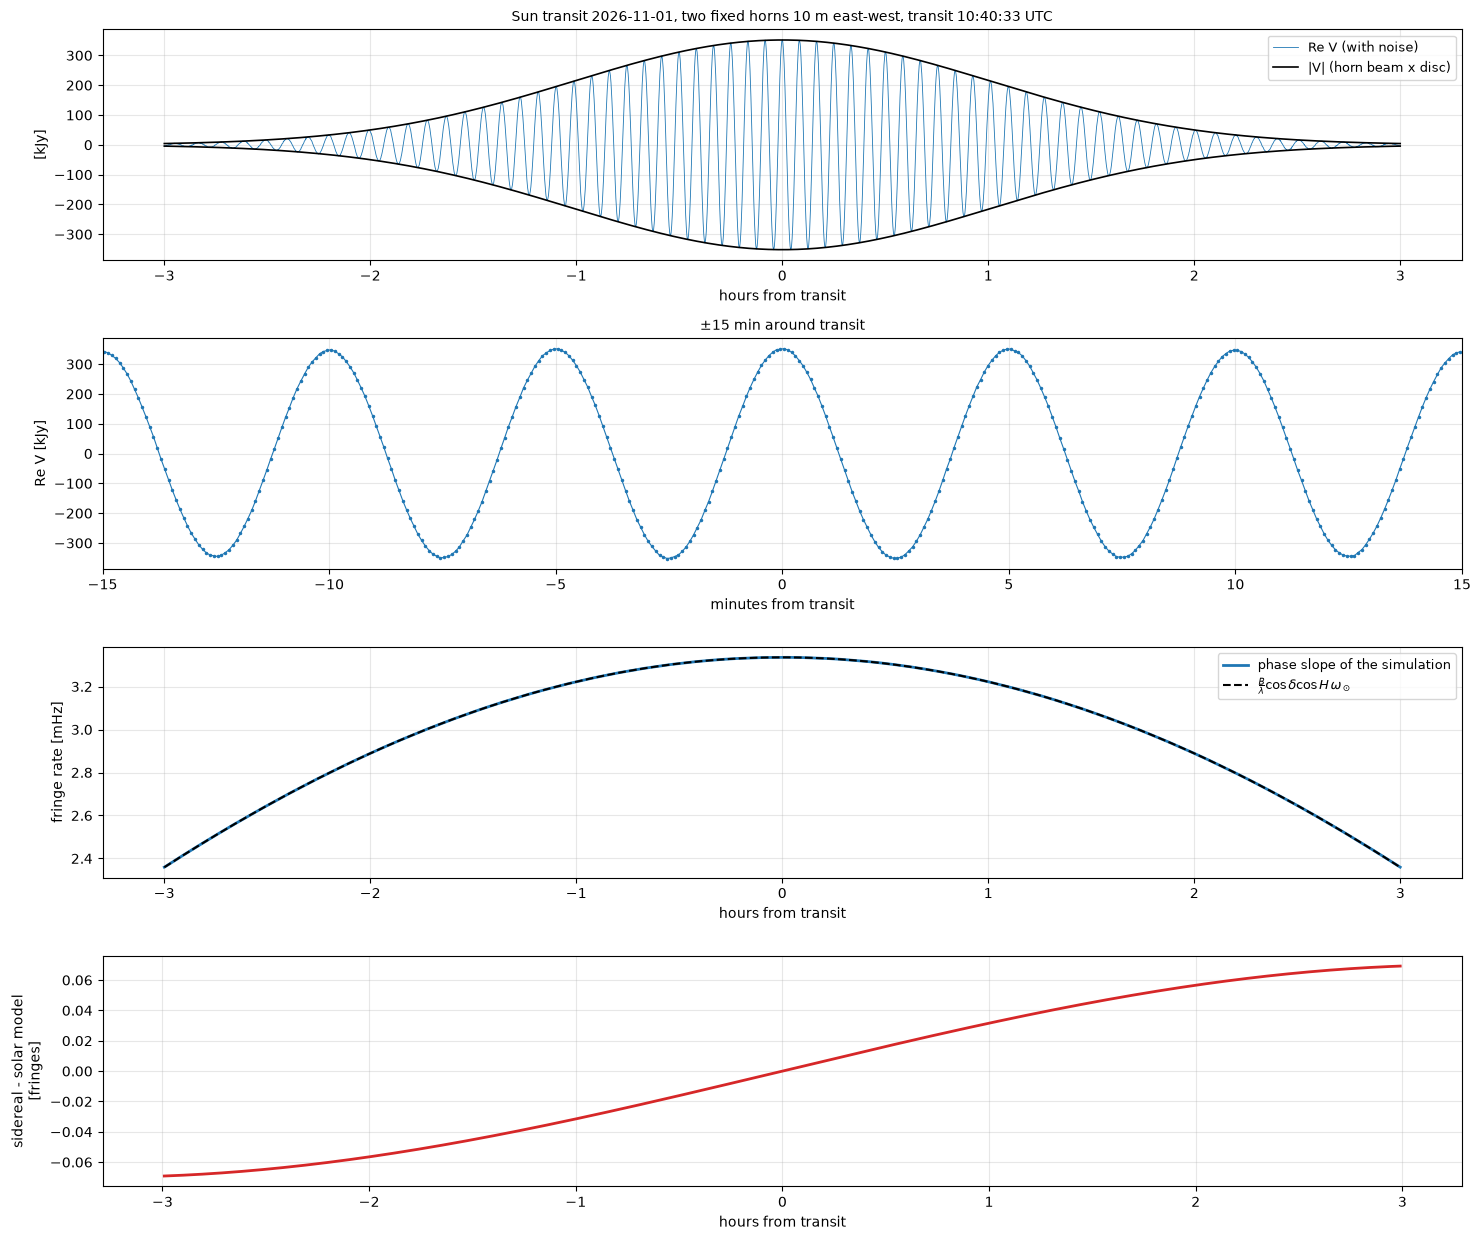

fringe rate at transit: simulation 3.336 mHz, prediction 3.336 mHz (period 5.00 min)
peak |V| 352 kJy = 0.738 x S (|V(10 m)| of the limb-brightened disc)
sidereal model after 2 h: 0.057 fringes off


In [7]:
sts = SolarTransitSimulator(horns, DATE, ha_range_h=(-3, 3), t_dump_s=5.0)
vt = sts.run(sun)
vt0 = SolarTransitSimulator(horns, DATE, ha_range_h=(-3, 3), t_dump_s=5.0, add_noise=False).run(sun)
t_h = (vt.time_mjd - T_TRANSIT) * 24
fig, axes = plt.subplots(4, 1, figsize=(15, 12.5))
axes[0].plot(t_h, vt.vis[:, 0].real / 1e3, lw=0.6, color="C0", label="Re V (with noise)")
axes[0].plot(t_h, np.abs(vt0.vis[:, 0]) / 1e3, color="k", lw=1.2, label="|V| (horn beam x disc)")
axes[0].plot(t_h, -np.abs(vt0.vis[:, 0]) / 1e3, color="k", lw=1.2)
axes[0].set_ylabel("[kJy]"); axes[0].legend(fontsize=9, loc="upper right")
axes[0].set_title(f"Sun transit {DATE}, two fixed horns 10 m east-west, transit {utc(T_TRANSIT)}", fontsize=10)
zoom = np.abs(t_h) < 0.25
axes[1].plot(t_h[zoom] * 60, vt.vis[zoom, 0].real / 1e3, ".-", ms=3, lw=0.8)
axes[1].set_ylabel("Re V [kJy]"); axes[1].set_title("±15 min around transit", fontsize=10)
axes[1].set_xlim(-15, 15)
ph = np.unwrap(np.angle(vt0.vis[:, 0]))
tt = (vt.time_mjd - vt.time_mjd[0]) * 86400
rate = np.gradient(ph, tt) / (2 * np.pi)
pred = 10 / LAM * np.cos(np.radians(dec_sun)) * np.cos(np.radians(vt.ha_deg)) * 2 * np.pi / 86400
axes[2].plot(t_h, 1e3 * rate, lw=2, label="phase slope of the simulation")
axes[2].plot(t_h, 1e3 * pred, "--", color="k", label=r"$\frac{B}{\lambda}\cos\delta\cos H\,\omega_\odot$")
axes[2].set_ylabel("fringe rate [mHz]"); axes[2].legend(fontsize=9)
# sidereal model with the same field centre
sun_fixed = SkyModel.from_json(CFG / "skies" / "sun_21cm.json"); sun_fixed.center = FieldCenter("Sun", ra_sun, dec_sun)
vs = TransitSimulator(horns, dec_deg=dec_sun, ha_range_h=(-3, 3), t_dump_s=5.0, add_noise=False, date=DATE).run(sun_fixed)
ph_s = np.interp(vt.time_mjd, vs.time_mjd, np.unwrap(np.angle(vs.vis[:, 0])))
ph_s = ph_s - ph_s[np.argmin(np.abs(t_h))] + ph[np.argmin(np.abs(t_h))]
inside = (vt.time_mjd >= vs.time_mjd[0]) & (vt.time_mjd <= vs.time_mjd[-1])
axes[3].plot(t_h[inside], ((ph_s - ph) / (2 * np.pi))[inside], lw=2, color="C3")
axes[3].set_ylabel("sidereal - solar model\n[fringes]")
for ax in axes: ax.grid(alpha=0.3); ax.set_xlabel("hours from transit")
axes[1].set_xlabel("minutes from transit")
fig.tight_layout(); plt.show()
k0 = np.argmin(np.abs(t_h))
print(f"fringe rate at transit: simulation {1e3 * rate[k0]:.3f} mHz, prediction {1e3 * pred[k0]:.3f} mHz "
      f"(period {1 / rate[k0] / 60:.2f} min)")
print(f"peak |V| {np.abs(vt0.vis[:, 0]).max() / 1e3:.0f} kJy = {np.abs(vt0.vis[:, 0]).max() / disc.flux_jy:.3f} x S "
      f"(|V(10 m)| of the limb-brightened disc)")
print(f"sidereal model after 2 h: {abs((ph_s - ph)[np.argmin(np.abs(t_h - 2))]) / (2 * np.pi):.3f} fringes off")

## 6. The result: the radio diameter of the Sun

Moving the horns apart step by step and measuring the fringe amplitude at each setting samples $|V(q)|$; the diameter follows from the curve, above all from the position of the null. The simulation is set up honestly: the "data" come from the **limb-brightened** Sun of the model (+50 %), each setting with 60 s at transit and 3 % calibration error (set-up, pointing) – but the fit uses the **uniform disc**, the usual first model. A second fit with the limb-brightened profile shows the effect of the model.

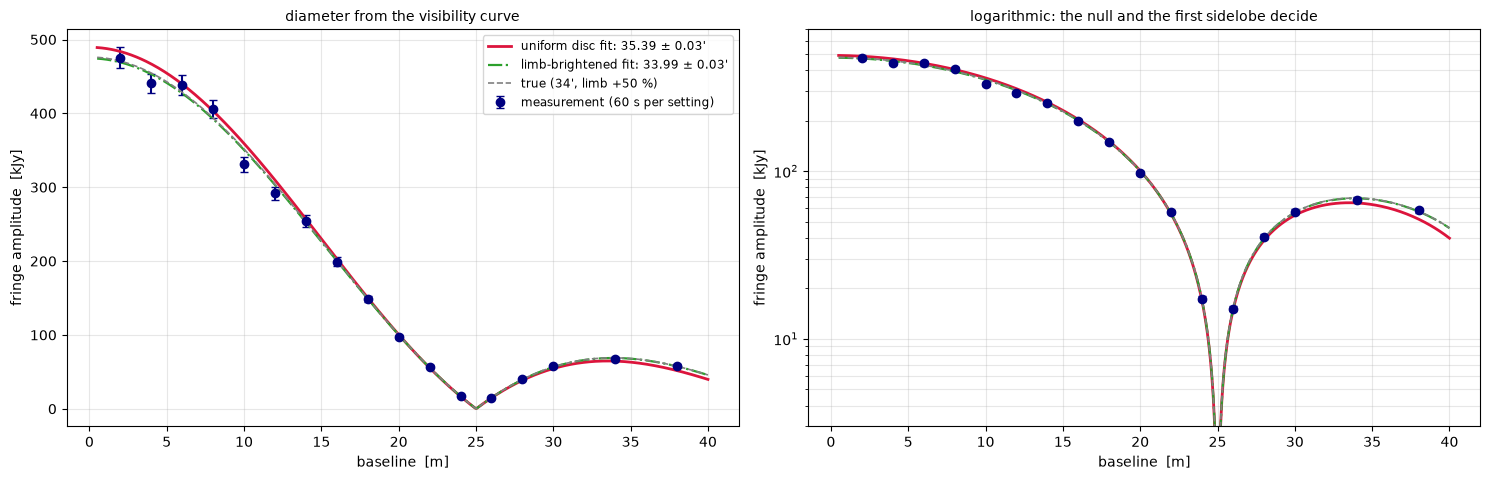

uniform disc      : 35.39 ± 0.03 arcmin  (true 34.00; deviation +4.1 %, formal error 0.09 %)
limb-brightened   : 33.99 ± 0.03 arcmin


In [8]:
B_MEAS = np.array([2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 34, 38.0])
rng = np.random.default_rng(42)
amp, sig, qm = [], [], []
for k, b in enumerate(B_MEAS):
    o = Observation.from_sky(sun, horn_pair(b), ha_range_h=(-30 / 3600, 30 / 3600), t_int_s=60, date=DATE, min_elev_deg=0)
    v = VisibilitySimulator(seed=k).run(sun, o)
    a = abs(v.vis[0, 0]) * (1 + 0.03 * rng.standard_normal())
    amp.append(a); sig.append(np.hypot(v.sigma[0, 0], 0.03 * a)); qm.append(np.hypot(v.u[0], v.v[0]))
amp, sig, qm = map(np.array, (amp, sig, qm))
s0, d, es, ed = fit_disc_diameter(qm, amp, sig, p0=(4e5, 0.5))

from scipy.optimize import curve_fit
def limb_model(qq, s, dia):
    return s * np.abs(DiscSource("S", 0, 0, 1.0, diameter_deg=dia, limb=0.5).visibility(qq, np.zeros_like(qq)))
pl, cl = curve_fit(limb_model, qm, amp, p0=(4e5, 0.5), sigma=sig, absolute_sigma=True)
el = np.sqrt(np.diag(cl))

bb = np.linspace(0.5, 40, 500); qq = bb / LAM
fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
for ax, log in zip(axes, (False, True)):
    ax.errorbar(B_MEAS, amp / 1e3, yerr=sig / 1e3, fmt="o", color="navy", capsize=3, label="measurement (60 s per setting)")
    ax.plot(bb, disc_amplitude(qq, s0, d) / 1e3, color="crimson", lw=2, label=f"uniform disc fit: {60 * d:.2f} ± {60 * ed:.2f}'")
    ax.plot(bb, limb_model(qq, *pl) / 1e3, color="C2", lw=1.6, ls="-.", label=f"limb-brightened fit: {60 * pl[1]:.2f} ± {60 * el[1]:.2f}'")
    ax.plot(bb, np.abs(disc.visibility(qq, np.zeros_like(qq))) / 1e3, "--", color="0.5", lw=1.2, label="true (34', limb +50 %)")
    ax.set_xlabel("baseline  [m]"); ax.set_ylabel("fringe amplitude  [kJy]"); ax.grid(alpha=0.3, which="both")
    if log: ax.set_yscale("log"); ax.set_ylim(3, 700)
axes[0].legend(fontsize=8.5); axes[0].set_title("diameter from the visibility curve", fontsize=10)
axes[1].set_title("logarithmic: the null and the first sidelobe decide", fontsize=10)
fig.tight_layout(); plt.show()
print(f"uniform disc      : {60 * d:.2f} ± {60 * ed:.2f} arcmin  (true 34.00; deviation {100 * (60 * d / 34 - 1):+.1f} %, formal error {100 * ed / d:.2f} %)")
print(f"limb-brightened   : {60 * pl[1]:.2f} ± {60 * el[1]:.2f} arcmin")

The formal error of the uniform-disc fit (about 0.1 %) faces a real deviation of about 4 %, because the wrong brightness profile was fitted: for a resolved source the **model** is the dominant source of error, not the noise. With the right profile the fit lands on the true diameter within its error.

## 7. Configuration and procedure

The B210 profile `b210.toml` with both RX channels: settings, data rate and the check of the profile against the data sheet (`Receiver.validate`).

In [9]:
rec2 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
rec2.rx_channels = 2
print(f"receiver          : {rec2.name}, {rec2.rx_channels} RX channels, common LO and clock")
print(f"centre frequency  : {rec2.center_freq_hz / 1e6:.3f} MHz (or 1415 MHz to avoid the HI line)")
print(f"sample rate       : {rec2.sample_rate_sps / 1e6:.1f} MS/s complex per channel, bandwidth {rec2.bandwidth_hz / 1e6:.1f} MHz")
print(f"settings          : AGC {'on' if rec2.agc else 'off'}, DC offset correction {'on' if rec2.dc_offset_correction else 'off'}, "
      f"IQ balance correction {'on' if rec2.iq_balance_correction else 'off'}, clock {rec2.clock_source}")
r = rec2.data_rate_bytes_per_s()
print(f"raw data rate     : {r / 1e6:.0f} MB/s ({rec2.sample_format}, both channels) = {r * 3600 / 1e9:.0f} GB/h; "
      f"correlated 5 s dumps of 64 channels: {64 * 8 * 3600 / 5 / 1e6:.1f} MB/h")
print(f"profile check     : {rec2.validate() or 'consistent with the data sheet'}")

receiver          : Ettus USRP B210, 2 RX channels, common LO and clock
centre frequency  : 1420.406 MHz (or 1415 MHz to avoid the HI line)
sample rate       : 2.0 MS/s complex per channel, bandwidth 2.0 MHz
settings          : AGC off, DC offset correction off, IQ balance correction off, clock internal
raw data rate     : 16 MB/s (sc16, both channels) = 58 GB/h; correlated 5 s dumps of 64 channels: 0.4 MB/h
profile check     : consistent with the data sheet


**Procedure of a session** (Appendix B):

| step | action | check |
|---|---|---|
| 1 | set up both horns east–west, measure the spacing (± 5 cm suffice) | baseline known to 0.5 % |
| 2 | cables of equal length – differences go straight into the phase | – |
| 3 | noise source with splitter on both inputs | channel phase and gain match (section 4) |
| 4 | point the horns at the Sun (34° beam: by eye) | – |
| 5 | record, correlate 5 s dumps, write amplitude and phase | – |
| 6 | the Sun drifts into the beam | **amplitude** rises (section 5) |
| 7 | follow the phase | advances linearly at the predicted **rate** |
| 8 | cover the horns | correlation drops to **zero**; what remains is crosstalk |
| 9 | do not retune between steps 3 and 8 | the channel phase stays constant |

**The most important check** is not the appearance of the fringes but their disappearance: with covered horns the correlation must go to zero. **After the single-site test** exactly three things change for the distributed baseline: separate frequency standards (notebook 03), time stamps from GPS-PPS, and the fringe search over delay and rate (notebook 05). Everything else – signal path, software, correlation, analysis – has then been tried out.

## 8. Selector

Date, baseline length and orientation, limb brightening of the model, dump time and hour-angle range; *Run Interact* shows the transit (real part, amplitude, phase slope) and the expected visibility amplitude over the baseline. (Needs a running kernel.)

In [10]:
import ipywidgets as widgets
from IPython.display import display

def run_sun(date, baseline_m, orientation, limb, t_dump_s, ha_half_h):
    s = SkyModel.from_json(CFG / "skies" / "sun_21cm.json")
    s.components[0].limb = limb
    arr = horn_pair(baseline_m, "east" if orientation == "east-west" else "north")
    t0 = solar_transit_mjd(date, site.lon_deg)
    _, dec = (float(x) for x in sun_radec_deg(t0))
    v = SolarTransitSimulator(arr, date, ha_range_h=(-ha_half_h, ha_half_h), t_dump_s=t_dump_s).run(s)
    v0 = SolarTransitSimulator(arr, date, ha_range_h=(-ha_half_h, ha_half_h), t_dump_s=t_dump_s, add_noise=False).run(s)
    th = (v.time_mjd - t0) * 24
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
    axes[0].plot(th, v.vis[:, 0].real / 1e3, lw=0.6); axes[0].plot(th, np.abs(v0.vis[:, 0]) / 1e3, "k", lw=1.2)
    axes[0].set(xlabel="hours from transit", ylabel="Re V, |V|  [kJy]", title=f"{arr.name}, {date}, transit {utc(t0)}")
    ph = np.unwrap(np.angle(v0.vis[:, 0])); tt = (v.time_mjd - v.time_mjd[0]) * 86400
    axes[1].plot(th, 1e3 * np.gradient(ph, tt) / (2 * np.pi), lw=2)
    axes[1].set(xlabel="hours from transit", ylabel="fringe rate  [mHz]", title=f"Dec {dec:+.1f} deg")
    bb = np.linspace(0.5, 60, 400)
    axes[2].semilogy(bb, np.abs(s.components[0].visibility(bb / LAM, np.zeros_like(bb))), lw=2)
    axes[2].axvline(baseline_m, color="C3", ls="--"); axes[2].set_ylim(1e-3, 1.2)
    axes[2].set(xlabel="baseline  [m]", ylabel="|V| / S", title=f"disc visibility, limb +{100 * limb:.0f} %")
    for ax in axes: ax.grid(alpha=0.3, which="both"); ax.title.set_fontsize(10)
    fig.tight_layout(); plt.show()
    print(f"elevation at transit {90 - site.lat_deg + dec:.1f} deg, peak |V| {np.abs(v0.vis[:, 0]).max() / 1e3:.0f} kJy, "
          f"S/N per dump at transit {np.abs(v0.vis[:, 0]).max() * np.sqrt(v.weight[:, 0].max()):.0f}")

display(widgets.interactive(
    run_sun, {"manual": True},
    date=widgets.Text(value=DATE, description="date (UTC)"),
    baseline_m=widgets.FloatSlider(value=10, min=1, max=60, step=0.5, description="baseline [m]"),
    orientation=widgets.ToggleButtons(options=["east-west", "north-south"], description="orientation"),
    limb=widgets.FloatSlider(value=0.5, min=0, max=2, step=0.1, description="limb"),
    t_dump_s=widgets.Dropdown(options=[1.0, 5.0, 10.0, 30.0], value=5.0, description="dump [s]"),
    ha_half_h=widgets.FloatSlider(value=3, min=0.25, max=5, step=0.25, description="±time [h]"),
))

interactive(children=(Text(value='2026-11-01', continuous_update=False, description='date (UTC)'), FloatSlider…